# 01 · Inventário passivo de ativos

**Objetivo:** descobrir o que existe na rede **só escutando**. É o primeiro passo de qualquer avaliação (62443-3-2) e corresponde ao requisito **SR 7.8** (*inventário de componentes*) e à categoria **ID.AM** do NIST CSF.

Por que passivo? Varreduras ativas (como um `nmap` agressivo) já derrubaram CLPs antigos em produção. Em OT, primeiro se escuta.

**Os dados:** `captures/baseline_day1.pcap`, dez minutos de tráfego da planta fictícia, gerados por `otsec/traffic.py`. São pacotes reais (abrem no Wireshark), mas ninguém tocou numa rede de verdade.

In [1]:
# Configuração: raiz do repositório no caminho de import, tabelas largas
import sys, pathlib, logging, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore"); logging.disable(logging.CRITICAL)
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
from IPython.display import Image, Markdown, display
from otsec.model import CAPTURES
from otsec import inventory as inv
from otsec.model import assets
df = inv.packets(CAPTURES / "baseline_day1.pcap")
print(f"{len(df)} pacotes TCP entre {inv.when(df.time.min())} e {inv.when(df.time.max())}")
df[["ts", "src", "dst", "sport", "dport", "tcp_flags", "payload_len", "fc"]].head(8)

4309 pacotes TCP entre 08:00:00 e 08:09:59


,ts,src,dst,sport,dport,tcp_flags,payload_len,fc
0,2026-11-13 08:00:00.036293030+00:00,127.0.20.21,127.0.10.11,44402,502,PA,12,3.0
1,2026-11-13 08:00:00.036293030+00:00,127.0.20.21,127.0.10.12,46879,502,PA,12,3.0
2,2026-11-13 08:00:00.041213989+00:00,127.0.10.12,127.0.20.21,502,46879,PA,29,3.0
3,2026-11-13 08:00:00.042335987+00:00,127.0.10.11,127.0.20.21,502,44402,PA,29,3.0
4,2026-11-13 08:00:00.099999905+00:00,127.0.20.21,127.0.10.11,44402,502,S,0,NaN
5,2026-11-13 08:00:00.099999905+00:00,127.0.20.21,127.0.10.12,46879,502,S,0,NaN
6,2026-11-13 08:00:00.100399971+00:00,127.0.10.11,127.0.20.21,502,44402,SA,0,NaN
7,2026-11-13 08:00:00.100399971+00:00,127.0.10.12,127.0.20.21,502,46879,SA,0,NaN


## 1. Quem está na rede

Cada IP que envia pacotes vira uma linha. Comparamos com a **lista documentada** de ativos (`model/plant.yaml`).

In [2]:
inventario = inv.inventory(df)
inventario

,ip,mac,asset,kind,zone,services_seen,talks_to,packets_sent
0,127.0.10.11,02:00:5e:3f:29:88,plc-1,PLC,cell,modbus,4,928
1,127.0.10.12,02:00:5e:05:3e:f3,plc-2,PLC,cell,modbus,2,902
2,127.0.20.21,02:00:5e:b6:a2:a9,hmi-1,HMI,supervision,rdp,3,1214
3,127.0.20.22,02:00:5e:4e:ec:dd,ews-1,EWS,supervision,,1,9
4,127.0.20.23,02:00:5e:8b:ab:30,scada-1,SCADA,supervision,opcua,4,848
5,127.0.30.31,02:00:5e:3b:63:71,hist-1,Historian,site_ops,,2,142
6,127.0.30.32,02:00:5e:1e:0f:ad,broker-1,Broker,site_ops,mqtt,3,62
7,127.0.35.41,02:00:5e:8d:85:4b,dmz-broker,Broker,dmz,mqtts,2,120
8,127.0.40.51,02:00:5e:ce:82:3b,office-1,Workstation,enterprise,,1,10
9,127.0.40.52,02:00:5e:c8:2f:94,erp-1,Server,enterprise,,2,74


**Leitura:** os dez dispositivos documentados apareceram e nenhum desconhecido. `services_seen` é o que cada um **oferece** na prática: o HMI tem **RDP aberto**, o que não estava em nenhum desenho de projeto. Esse tipo de descoberta é comum: acesso remoto instalado "temporariamente" por um suporte e nunca removido.

## 2. Quem fala com quem

In [3]:
fluxos = inv.flows(df)
fluxos

,src_id,dst_id,dport,packets,bytes,service,src_zone,dst_zone
0,erp-1,broker-1,1883,14,1190,mqtt,enterprise,site_ops
1,erp-1,dmz-broker,8883,60,21240,mqtts,enterprise,dmz
2,office-1,hmi-1,3389,10,9540,rdp,enterprise,supervision
3,broker-1,dmz-broker,8883,60,27240,mqtts,site_ops,dmz
4,hist-1,plc-1,502,20,1320,modbus,site_ops,cell
5,hist-1,scada-1,4840,122,35388,opcua,site_ops,supervision
6,ews-1,plc-1,502,9,531,modbus,supervision,cell
7,hmi-1,plc-1,502,602,39708,modbus,supervision,cell
8,hmi-1,plc-2,502,602,39708,modbus,supervision,cell
9,scada-1,broker-1,1883,123,14728,mqtt,supervision,site_ops


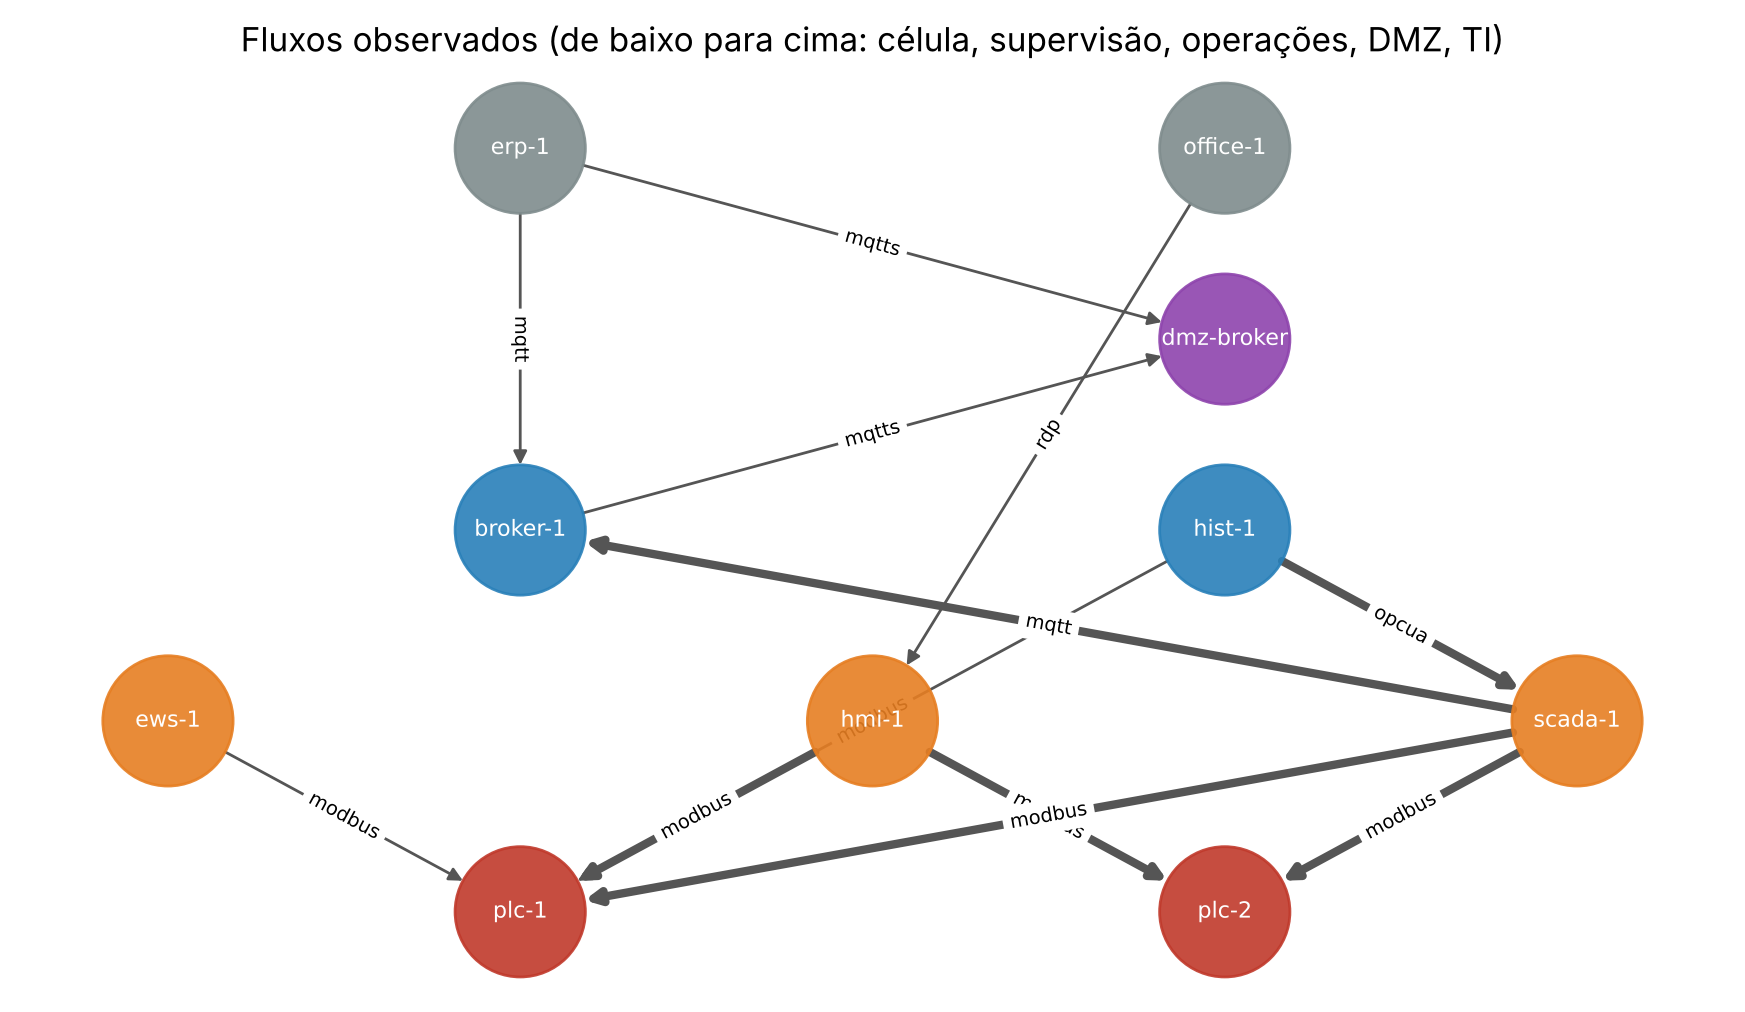

In [4]:
import networkx as nx
G = nx.DiGraph()
for f in fluxos.itertuples():
    G.add_edge(f.src_id, f.dst_id, label=f.service, w=f.packets)
cores = {"cell": "#c0392b", "supervision": "#e67e22", "site_ops": "#2980b9", "dmz": "#8e44ad", "enterprise": "#7f8c8d"}
from otsec.model import asset_zone
z = asset_zone()
nivel = {"cell": 0, "supervision": 1, "site_ops": 2, "dmz": 3, "enterprise": 4}
pos = {}
for zona, n in nivel.items():
    nos = [a for a in G if z.get(a) == zona]
    for i, a in enumerate(sorted(nos)): pos[a] = (i - len(nos) / 2 + (0.5 if zona == "dmz" else 0), n)
plt.figure(figsize=(11, 6))
nx.draw_networkx_nodes(G, pos, node_color=[cores[z[n]] for n in G], node_size=2200, alpha=.9)
nx.draw_networkx_labels(G, pos, font_size=8, font_color="white")
nx.draw_networkx_edges(G, pos, width=[1 + 2 * (d["w"] > 100) for *_, d in G.edges(data=True)], arrows=True, node_size=2200, edge_color="#555")
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): d["label"] for u, v, d in G.edges(data=True)}, font_size=7)
plt.title("Fluxos observados (de baixo para cima: célula, supervisão, operações, DMZ, TI)"); plt.axis("off"); plt.show()

Já dá para ver setas que **pulam camadas**: o PC do escritório (TI, topo) chega no HMI, e o ERP chega direto no broker da planta. O exercício 02 transforma essa impressão em violações formais.

## 3. O que o Modbus revela

Modbus não tem autenticação nem criptografia. Quem escuta vê tudo: quem lê, quem escreve, em qual registrador.

In [5]:
inv.modbus_summary(df)

,src_id,dst_id,function,write,requests
0,ews-1,plc-1,write multiple registers,True,3
1,hist-1,plc-1,read holding registers,False,20
2,hmi-1,plc-1,read holding registers,False,600
3,hmi-1,plc-2,read holding registers,False,600
4,scada-1,plc-1,read holding registers,False,300
5,scada-1,plc-2,read holding registers,False,300


Só a **ews-1** (estação de engenharia) escreve, e só no registrador 100 (setpoint de velocidade). Isso é uma **linha de base**: no exercício 06, qualquer escrita fora desse padrão vira alerta. O historiador lendo o PLC diretamente é outra anomalia de arquitetura: ele deveria ler pelo SCADA (OPC UA).

## 4. O que o MQTT em texto aberto revela

In [6]:
inv.mqtt_secrets(df)

,ts,src_id,mqtt,user,password,topic,message
28,2026-11-13 08:00:00.436292887+00:00,scada-1,PUBLISH,NaN,NaN,acme/sao-paulo/packaging/line-1/filler-01/speed,"{""value"": 441.9}"
29,2026-11-13 08:00:00.500000+00:00,scada-1,CONNECT,scada,Acme2024!,NaN,NaN
39,2026-11-13 08:00:00.936292887+00:00,erp-1,PUBLISH,NaN,NaN,acme/erp/report,"{""ok"": true}"


**A senha do SCADA está legível na captura** (`Acme2024!`), junto com tópicos e valores de processo. Qualquer pessoa com acesso a uma porta espelhada do switch tem as credenciais. Isso é a técnica **T0842 Network Sniffing** do ATT&CK for ICS, e é corrigido no exercício 05 com TLS.

## 5. E num dia com intruso?

A captura `attack.pcap` tem o mesmo dia normal mais um notebook desconhecido ligado na rede.

In [7]:
ataque = inv.packets(CAPTURES / "attack.pcap")
inv.inventory(ataque).query("asset == 'NOT IN INVENTORY'")

,ip,mac,asset,kind,zone,services_seen,talks_to,packets_sent
10,127.0.40.66,02:66:66:66:66:66,NOT IN INVENTORY,?,?,,30,1546


Um IP e um MAC que **não estão no inventário**, falando com 30 endereços. O inventário passivo, comparado com a lista documentada, já é um detector simples de dispositivo intruso.

## Resumo

* Inventário passivo: zero risco para a planta, e já mostra **serviços esquecidos** (RDP), **caminhos fora do projeto** e **credenciais expostas**.
* A comparação "documentado × observado" é o ponto de partida de tudo: zonas (02), risco (03), firewall (04) e IDS (06).
* Controle `CTL-INV`, evidência: `tests/test_inventory.py`.